guys first we need to light cleaning standardization

- [ ] Jupyter notebook — data wrangling and ML code, markdown commentary, and outputs, running endto\-end without errors\.

- [ ]
Cleaning & transformation log — can be embedded in the notebook as markdown or submitted as a
short separate document\.

- [ ]
Power BI file \(\.pbix\) — dashboard connected to final dataset/model outputs, plus a PDF export as a
fallback\.

- [ ]
Written report \(5–7 pages\) — objective, dataset description, methodology per pipeline stage, ML
approach and results, dashboard walkthrough, insights, limitations\. Word or PDF\.

- [ ]
Presentation deck \(8–10 slides\) for the viva, including a live or screen\-recorded dashboard demo\.


- [ ] Raw and cleaned dataset files \(or a script to regenerate them, if the raw file is too large to submit\)\.

- [ ]
Individual contribution statement — one line per member describing their primary responsibility

4\.1 Data Extraction
• Document how and from where the data was obtained \(download, API call, scrape, or DB query\)\.
• Note any access constraints, rate limits, authentication, or licensing terms encountered\.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata
import os
from pathlib import Path
import sqlite3

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Global log list — will hold 4.3 + 4.4 entries
cleaning_log_rows = []

def log_step(city, column, action, detail, rows=None):
    cleaning_log_rows.append({
        "city":   city,
        "column": column,
        "action": action,
        "detail": detail,
        "rows":   rows,
    })

In [ ]:
from pathlib import Path
folder_path = Path("/content/drive/MyDrive/AirBNB/airbnb.db")

db_path = folder_path / "airbnb.db"
log_path = folder_path / "cleaning_log.csv"

print(f"Folder exists: {folder_path.exists()}")
print(f"Database file accessible: {db_path.exists()}")
print(f"Cleaning log accessible: {log_path.exists()}")

if db_path.exists():
    print(f"Database file size: {db_path.stat().st_size / (1024 * 1024):.1f} MB")

Folder exists: True
Database file accessible: False
Cleaning log accessible: False


In [ ]:
from pathlib import Path

# Search for your database file anywhere inside MyDrive
drive_root = Path("/content/drive/MyDrive")
found_dbs = list(drive_root.glob("**/airbnb.db"))

if found_dbs:
    print(f"Found your database at: {found_dbs[0]}")
    # You can get the parent folder path directly:
    my_folder = found_dbs[0].parent
    print(f"Your folder path is: {my_folder}")
else:
    print("Could not find airbnb.db in MyDrive. Make sure it's uploaded to your Drive!")

Found your database at: /content/drive/MyDrive/AirBNB/airbnb.db
Your folder path is: /content/drive/MyDrive/AirBNB


4\.5 Insights & Communication
• At least 3 concrete, non\-obvious insights, each backed by a visualization or summary statistic\.
• A short discussion of limitations what the data cannot tell you, and any wrangling decisions that could
bias conclusions

In [ ]:
# load data from SQLite
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Corrected path to point to your ML folder
DB_PATH = "/content/drive/MyDrive/AirBNB/airbnb.db"
conn = sqlite3.connect(DB_PATH)

# ---- Listings — main analysis table
listings = pd.read_sql("SELECT * FROM listings", conn)

# ---- Reviews — for one time-series insight
reviews = pd.read_sql("SELECT listing_id, date, city FROM reviews", conn)

conn.close()

# ---- Quick sanity
print(f"listings: {listings.shape}")
print(f"reviews:  {reviews.shape}")
print(f"\nlistings dtypes (numeric only):")
print(listings.select_dtypes(include=[np.number]).dtypes.to_string())

# ---- Set plotting defaults once
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

print("\n Data loaded. Ready for insight cells.")

listings: (74015, 49)
reviews:  (2728890, 3)

listings dtypes (numeric only):
accommodates                        int64
availability_30                     int64
availability_365                    int64
availability_60                     int64
availability_90                     int64
bedrooms                          float64
beds                              float64
calculated_host_listings_count      int64
host_has_profile_pic              float64
host_id                             int64
host_identity_verified            float64
host_is_superhost                 float64
id                                  int64
latitude                          float64
longitude                         float64
maximum_nights                    float64
minimum_nights                    float64
number_of_reviews                   int64
price                             float64
review_scores_accuracy            float64
review_scores_checkin             float64
review_scores_cleanliness         float6

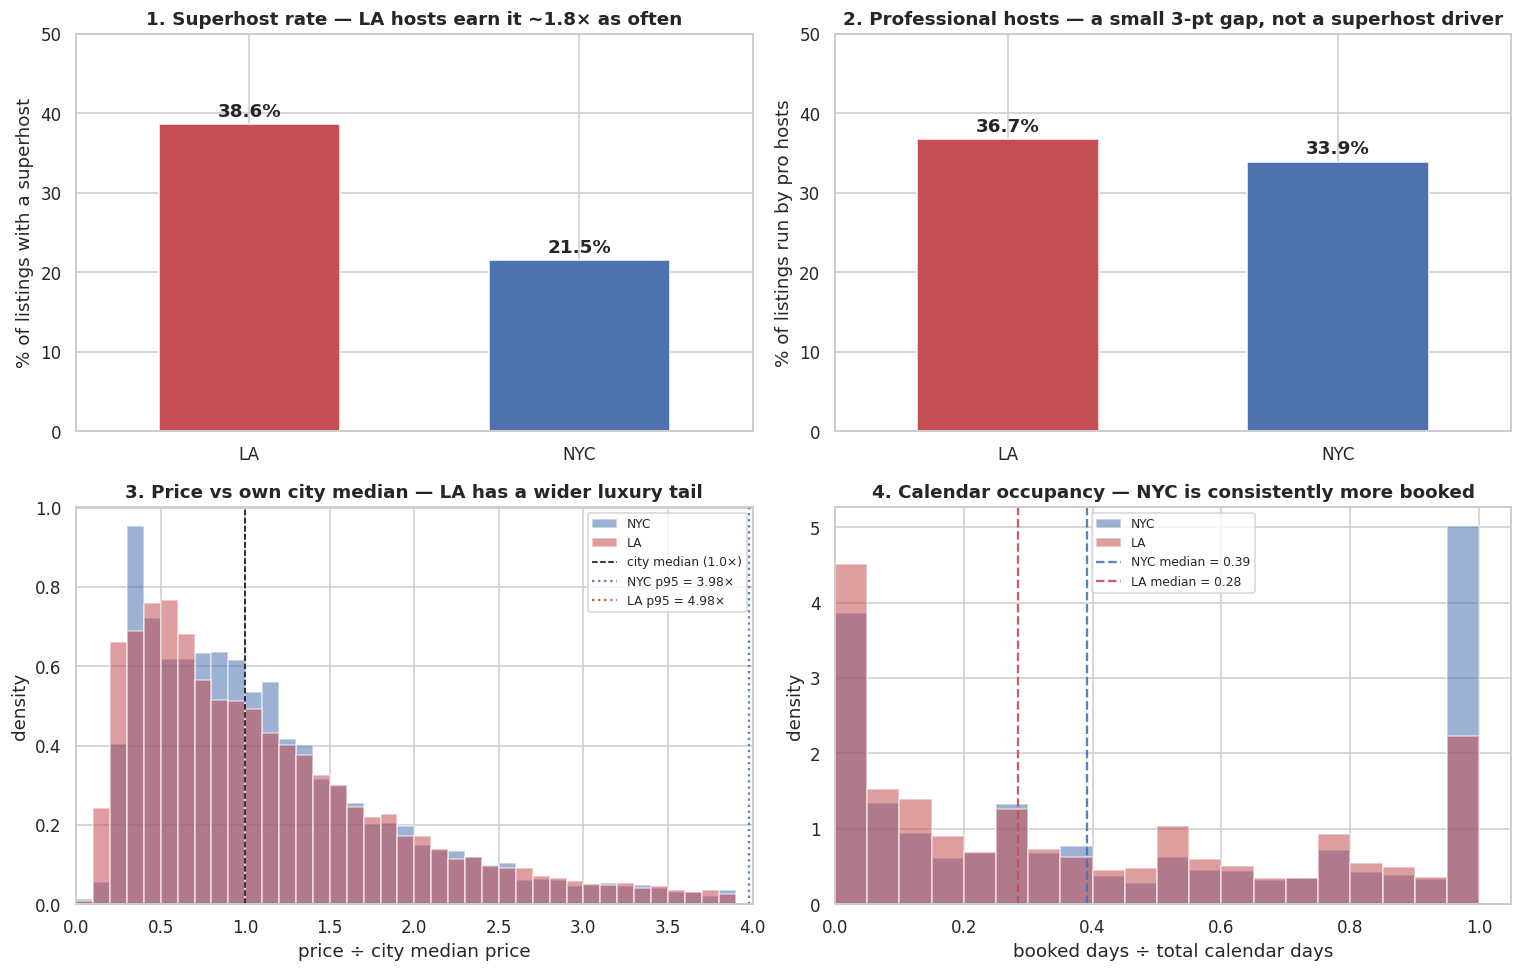

SUMMARY STATS BACKING EACH INSIGHT

1. Superhost rate by city (%):
city
LA     38.64
NYC    21.51

2. Professional-host rate by city (%):
city
LA     36.73
NYC    33.89

3. price ÷ city median — mean, p95 by city:
       mean  median    p95
city                      
LA    1.549     1.0  4.982
NYC   1.423     1.0  3.978

4. Calendar occupancy — mean, median by city:
       mean  median
city               
LA    0.387   0.285
NYC   0.479   0.392

LEAD INSIGHT — The superhost paradox
LA has 38.6% superhosts (NYC: 21.5%),
yet NYC listings are MORE booked (median 0.39 vs LA 0.28).
→ Superhost status is a quality signal, not a demand signal.


In [ ]:
# =========================================================
# 4.5 INSIGHTS — four non-obvious findings
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# ---------------------------------------------------------
# INSIGHT 1 — LA hosts earn superhost ~1.8× as often
# ---------------------------------------------------------
sh = (listings.dropna(subset=["host_is_superhost"])
              .groupby("city", observed=True)["host_is_superhost"]
              .mean().mul(100))

ax = axes[0, 0]
sh.plot(kind="bar", ax=ax, color=["#C44E52", "#4C72B0"], width=0.55)
ax.set_title("1. Superhost rate — LA hosts earn it ~1.8× as often")
ax.set_ylabel("% of listings with a superhost")
ax.set_xlabel("")
ax.set_ylim(0, 50)
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(sh.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

# ---------------------------------------------------------
# INSIGHT 2 — LA has a slightly larger professional-host share
# ---------------------------------------------------------
ph = (listings.dropna(subset=["is_professional_host"])
              .groupby("city", observed=True)["is_professional_host"]
              .mean().mul(100))

ax = axes[0, 1]
ph.plot(kind="bar", ax=ax, color=["#C44E52", "#4C72B0"], width=0.55)
ax.set_title("2. Professional hosts — a small 3-pt gap, not a superhost driver")
ax.set_ylabel("% of listings run by pro hosts")
ax.set_xlabel("")
ax.set_ylim(0, 50)
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(ph.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")

# ---------------------------------------------------------
# INSIGHT 3 — LA has fatter price tails (after city normalisation)
# ---------------------------------------------------------
ax = axes[1, 0]
p95_vals = {}
for city, colour in [("NYC", "#4C72B0"), ("LA", "#C44E52")]:
    subset = listings.loc[listings["city"] == city,
                          "price_vs_city_median"].dropna()
    ax.hist(subset, bins=np.arange(0, 4, 0.1),
            alpha=0.55, label=city, color=colour, density=True)
    p95_vals[city] = subset.quantile(0.95)

ax.axvline(1.0, color="black", linestyle="--", linewidth=1,
           label="city median (1.0×)")
ax.axvline(p95_vals["NYC"], color="#4C72B0", linestyle=":",
           linewidth=1.5, alpha=0.9,
           label=f"NYC p95 = {p95_vals['NYC']:.2f}×")
ax.axvline(p95_vals["LA"], color="#C44E52", linestyle=":",
           linewidth=1.5, alpha=0.9,
           label=f"LA p95 = {p95_vals['LA']:.2f}×")

ax.set_title("3. Price vs own city median — LA has a wider luxury tail")
ax.set_xlabel("price ÷ city median price")
ax.set_ylabel("density")
ax.set_xlim(0, 4)
ax.legend(fontsize=8, loc="upper right")

# ---------------------------------------------------------
# INSIGHT 4 — The superhost paradox: NYC is more booked
#             despite fewer superhosts
# ---------------------------------------------------------
ax = axes[1, 1]
med_vals = {}
for city, colour in [("NYC", "#4C72B0"), ("LA", "#C44E52")]:
    subset = listings.loc[listings["city"] == city,
                          "cal_occupancy_rate"].dropna()
    ax.hist(subset, bins=np.arange(0, 1.05, 0.05),
            alpha=0.55, label=city, color=colour, density=True)
    med_vals[city] = subset.median()

for city, colour in [("NYC", "#4C72B0"), ("LA", "#C44E52")]:
    ax.axvline(med_vals[city], color=colour, linestyle="--",
               linewidth=1.5, alpha=0.9,
               label=f"{city} median = {med_vals[city]:.2f}")

ax.set_title("4. Calendar occupancy — NYC is consistently more booked")
ax.set_xlabel("booked days ÷ total calendar days")
ax.set_ylabel("density")
ax.set_xlim(0, 1.05)
ax.legend(fontsize=8, loc="upper center")

plt.tight_layout()
# Corrected the path to point to your actual 'ML' directory in Drive
plt.savefig("/content/drive/MyDrive/AirBNB/insight_4panel.png", dpi=110, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------
# SUMMARY STATS — the numbers behind each insight
# ---------------------------------------------------------
print("=" * 65)
print("SUMMARY STATS BACKING EACH INSIGHT")
print("=" * 65)

print("\n1. Superhost rate by city (%):")
print(sh.round(2).to_string())

print("\n2. Professional-host rate by city (%):")
print(ph.round(2).to_string())

print("\n3. price ÷ city median — mean, p95 by city:")
stats3 = (listings.groupby("city", observed=True)["price_vs_city_median"]
                  .agg(mean="mean", median="median",
                       p95=lambda s: s.quantile(0.95))
                  .round(3))
print(stats3.to_string())

print("\n4. Calendar occupancy — mean, median by city:")
stats4 = (listings.groupby("city", observed=True)["cal_occupancy_rate"]
                  .agg(mean="mean", median="median")
                  .round(3))
print(stats4.to_string())

# Lead insight framing
print("\n" + "=" * 65)
print("LEAD INSIGHT — The superhost paradox")
print("=" * 65)
print(f"LA has {sh['LA']:.1f}% superhosts (NYC: {sh['NYC']:.1f}%),")
print(f"yet NYC listings are MORE booked "
      f"(median {stats4.loc['NYC','median']:.2f} vs LA "
      f"{stats4.loc['LA','median']:.2f}).")
print("→ Superhost status is a quality signal, not a demand signal.")

In [ ]:
import sqlite3
import pandas as pd

# Corrected the path from AirBNB to ML
DB_PATH = "/content/drive/MyDrive/AirBNB/airbnb.db"
conn = sqlite3.connect(DB_PATH)

# What tables exist?
tables = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table'", conn
)
print("Tables:", tables["name"].tolist())

# Listings — this is your df_all from Deepnote
df = pd.read_sql("SELECT * FROM listings LIMIT 3", conn)
print(f"\nListings columns ({len(df.columns)}):")
print(df.columns.tolist())

# Reviews
n_reviews = pd.read_sql("SELECT COUNT(*) AS n FROM reviews", conn)["n"].iloc[0]
print(f"\nReviews rows: {n_reviews:,}")

conn.close()

Tables: ['listings', 'reviews']

Listings columns (49):
['accommodates', 'availability_30', 'availability_365', 'availability_60', 'availability_90', 'bedrooms', 'beds', 'calculated_host_listings_count', 'city', 'first_review', 'host_has_profile_pic', 'host_id', 'host_identity_verified', 'host_is_superhost', 'id', 'last_review', 'latitude', 'license_category', 'longitude', 'maximum_nights', 'minimum_nights', 'neighbourhood', 'neighbourhood_group', 'number_of_reviews', 'price', 'property_type', 'review_scores_accuracy', 'review_scores_checkin', 'review_scores_cleanliness', 'review_scores_communication', 'review_scores_location', 'review_scores_rating', 'review_scores_value', 'reviews_per_month', 'room_type', 'city_neighbourhood', 'cal_booked_days', 'cal_min_min_nights', 'cal_max_max_nights', 'cal_occupancy_rate', 'host_tenure_months', 'host_portfolio_bucket', 'price_vs_city_median', 'reviews_per_host_year', 'is_professional_host', 'reviews_total', 'reviews_last_90d', 'reviews_last_365d'

4\.6 Machine Learning
• Frame at least one ML task on the wrangled dataset — classification, regression, clustering, or
forecasting, whichever fits the data and question\.
• Justify the model choice\(s\); compare at least two algorithms or one algorithm against a simple baseline\.
• Follow proper methodology: train/test \(or train/validation/test\) split, appropriate preprocessing
\(scaling/encoding\) fit only on training data, and cross\-validation where feasible\.
• Report evaluation metrics appropriate to the task \(e\.g\. accuracy/precision/recall/F1/ROC\-AUC for
classification; RMSE/MAE/R² for regression\) and interpret them honestly, including where the model
underperforms\.


In [ ]:
# =========================================================
# 4.6a PREPROCESSING — regression + classification
# =========================================================
import sqlite3
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

DB_PATH = "/content/drive/MyDrive/AirBNB/airbnb.db"

# =========================================================
# 1. LOAD
# =========================================================
conn = sqlite3.connect(DB_PATH)
df = pd.read_sql("SELECT * FROM listings", conn)
conn.close()
print(f"Raw: {df.shape}")

# Restore dtypes SQLite flattened
for col in ["host_is_superhost", "is_professional_host",
            "host_has_profile_pic", "host_identity_verified"]:
    df[col] = df[col].map({1: True, 0: False}).astype("boolean")

for col in ["first_review", "last_review"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# =========================================================
# 2. FEATURE DEFINITIONS
# =========================================================

DROP_ALWAYS = [
    "id",
    "latitude", "longitude",
    "city_neighbourhood",
    "price_vs_city_median",
    "host_portfolio_bucket",
]

NUMERIC_COLS = [
    # Property
    "accommodates", "bedrooms", "beds",
    "minimum_nights", "maximum_nights",
    # Availability
    "availability_30", "availability_60", "availability_90", "availability_365",
    # Review volume + recency
    "number_of_reviews", "reviews_per_month", "reviews_total",
    "reviews_last_90d", "reviews_last_365d", "review_recency_days",
    # Review quality subscores
    "review_scores_accuracy", "review_scores_cleanliness",
    "review_scores_checkin", "review_scores_communication",
    "review_scores_location", "review_scores_value", "review_scores_rating",
    # Host
    "calculated_host_listings_count", "host_tenure_months",
    "reviews_per_host_year",
    # Calendar
    "cal_booked_days", "cal_occupancy_rate",
    "cal_min_min_nights", "cal_max_max_nights",
]

CATEGORICAL_COLS = [
    "city", "room_type", "property_type",
    "neighbourhood_group", "neighbourhood",
    "license_category",
]

# --- Narrow leakage for classification
# Airbnb superhost criteria: rating ≥ 4.8, ≥10 stays/yr, <1% cancel, ≥90% response.
# Every review-quality column is a direct or decomposed measure of the rating
# threshold. Every rolling-window review-activity column is a proxy for the
# 10-stays/yr rule. Dropping the whole family avoids a tautological model.
LEAKY_FOR_CLF = [
    "review_scores_rating", "review_scores_accuracy",
    "review_scores_cleanliness", "review_scores_checkin",
    "review_scores_communication", "review_scores_location",
    "review_scores_value",
    "reviews_last_365d", "reviews_last_90d",
    "reviews_per_month", "reviews_per_host_year",
    "review_recency_days",
]

NUMERIC_COLS_CLF = [c for c in NUMERIC_COLS if c not in LEAKY_FOR_CLF]

FEATURE_COLS_REG = NUMERIC_COLS + CATEGORICAL_COLS
FEATURE_COLS_CLF = NUMERIC_COLS_CLF + CATEGORICAL_COLS

print(f"\nRegression features:     {len(FEATURE_COLS_REG)} "
      f"({len(NUMERIC_COLS)} numeric + {len(CATEGORICAL_COLS)} categorical)")
print(f"Classification features: {len(FEATURE_COLS_CLF)} "
      f"({len(NUMERIC_COLS_CLF)} numeric + {len(CATEGORICAL_COLS)} categorical)  "
      f"[dropped {len(LEAKY_FOR_CLF)} leaky columns]")

# =========================================================
# 3. TASK 1 — REGRESSION SPLIT (with price clipping)
# =========================================================
print("\n" + "=" * 60)
print("TASK 1 — REGRESSION: price")
print("=" * 60)

df_reg = df.dropna(subset=["price"]).copy()

# ---- Clip price at the 99th percentile PER CITY
# The top listings are legitimate luxury properties ($31k/night Bel-Air villa),
# not data errors. But they dominate the regression loss. Clip them.
p99_per_row = df_reg.groupby("city", observed=True)["price"].transform(
    lambda s: s.quantile(0.99)
)
n_clipped = (df_reg["price"] > p99_per_row).sum()
p99_nyc = df_reg.loc[df_reg["city"] == "NYC", "price"].quantile(0.99)
p99_la  = df_reg.loc[df_reg["city"] == "LA",  "price"].quantile(0.99)
max_before = df_reg["price"].max()

df_reg["price"] = df_reg["price"].clip(upper=p99_per_row)

print(f"Price clipped at p99 per city:")
print(f"  rows capped: {n_clipped:,}  ({n_clipped/len(df_reg)*100:.2f}%)")
print(f"  max before:  ${max_before:,.0f}")
print(f"  max after:   ${df_reg['price'].max():,.0f}")
print(f"  p99 NYC:     ${p99_nyc:,.0f}")
print(f"  p99 LA:      ${p99_la:,.0f}")

X_reg = df_reg[FEATURE_COLS_REG]
y_reg = np.log1p(df_reg["price"])

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42,
)
print(f"\nRows: {len(df_reg):,}")
print(f"Train: {X_train_reg.shape}   Test: {X_test_reg.shape}")
print(f"price (raw): min=${df_reg['price'].min():.0f}  "
      f"median=${df_reg['price'].median():.0f}  "
      f"max=${df_reg['price'].max():.0f}")

# =========================================================
# 4. TASK 2 — CLASSIFICATION SPLIT
# =========================================================
print("\n" + "=" * 60)
print("TASK 2 — CLASSIFICATION: host_is_superhost")
print("=" * 60)

df_clf = df.dropna(subset=["host_is_superhost"]).copy()
X_clf  = df_clf[FEATURE_COLS_CLF]
y_clf  = df_clf["host_is_superhost"].astype(int)

strat_key = df_clf["city"].astype(str) + "_" + y_clf.astype(str)

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=strat_key,
)
print(f"Rows: {len(df_clf):,}")
print(f"Train: {X_train_clf.shape}   Test: {X_test_clf.shape}")
print(f"Train superhost rate: {y_train_clf.mean():.3f}")
print(f"Test  superhost rate: {y_test_clf.mean():.3f}")

print(f"\nTrain superhost rate by city:")
print(df_clf.loc[X_train_clf.index]
      .groupby("city", observed=True)["host_is_superhost"]
      .mean().round(3).to_string())

# =========================================================
# 5. PREPROCESSING PIPELINES
# =========================================================
def make_preprocessor(numeric_cols, categorical_cols, for_tree=False):
    """
    ColumnTransformer:
      - numeric: impute median; scale only for linear models
      - categorical: impute "Missing"; one-hot with rare-category merge
    """
    if for_tree:
        num_pipe = Pipeline([("impute", SimpleImputer(strategy="median"))])
    else:
        num_pipe = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale",  StandardScaler()),
        ])

    cat_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encode", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=50,                                     #we changed this from 20 to 50, change later on based on perform
            sparse_output=False,
        )),
    ])

    return ColumnTransformer([
        ("num", num_pipe, numeric_cols),
        ("cat", cat_pipe, categorical_cols),
    ], remainder="drop")


prep_reg_linear = make_preprocessor(NUMERIC_COLS,     CATEGORICAL_COLS, for_tree=False)
prep_reg_tree   = make_preprocessor(NUMERIC_COLS,     CATEGORICAL_COLS, for_tree=True)
prep_clf_linear = make_preprocessor(NUMERIC_COLS_CLF, CATEGORICAL_COLS, for_tree=False)
prep_clf_tree   = make_preprocessor(NUMERIC_COLS_CLF, CATEGORICAL_COLS, for_tree=True)

print("\n" + "=" * 60)
print("PREPROCESSORS READY")
print("=" * 60)
print("  Regression linear: impute(median) + scale + one-hot")
print("  Regression tree:   impute(median) + one-hot")
print("  Classif. linear:   impute(median) + scale + one-hot")
print("  Classif. tree:     impute(median) + one-hot")

# =========================================================
# 6. SANITY CHECKS
# =========================================================
print("\n" + "=" * 60)
print("SANITY CHECKS")
print("=" * 60)

assert "price" not in FEATURE_COLS_REG
assert "host_is_superhost" not in FEATURE_COLS_CLF
print("Targets not in feature sets")

assert not (set(FEATURE_COLS_CLF) & set(LEAKY_FOR_CLF))
print(f"No leaky columns in classification features "
      f"({len(LEAKY_FOR_CLF)} dropped)")

assert not set(NUMERIC_COLS) & set(CATEGORICAL_COLS)
print("Numeric and categorical features are disjoint")

print(f"\nRegression target (log1p price):")
print(f"  Train mean: {y_train_reg.mean():.3f}")
print(f"  Test  mean: {y_test_reg.mean():.3f}")

print(f"\nClassification target:")
print(f"  Train superhost rate: {y_train_clf.mean():.3f}")
print(f"  Test  superhost rate: {y_test_clf.mean():.3f}")

# =========================================================
# 7. SHAPE CHECK
# =========================================================
X_train_reg_pp = prep_reg_linear.fit_transform(X_train_reg)
X_train_clf_pp = prep_clf_tree.fit_transform(X_train_clf)
print(f"\nRegression preprocessor output:     {X_train_reg_pp.shape}")
print(f"Classification preprocessor output: {X_train_clf_pp.shape}")

# Rebuild preprocessors fresh so no state carries into the model block
prep_reg_linear = make_preprocessor(NUMERIC_COLS,     CATEGORICAL_COLS, for_tree=False)
prep_reg_tree   = make_preprocessor(NUMERIC_COLS,     CATEGORICAL_COLS, for_tree=True)
prep_clf_linear = make_preprocessor(NUMERIC_COLS_CLF, CATEGORICAL_COLS, for_tree=False)
prep_clf_tree   = make_preprocessor(NUMERIC_COLS_CLF, CATEGORICAL_COLS, for_tree=True)

# =========================================================
# 8. STATE READY
# =========================================================
print("\n" + "=" * 60)
print("STATE READY FOR MODELLING")
print("=" * 60)
print(f"  X_train_reg: {X_train_reg.shape}   y_train_reg: {y_train_reg.shape}")
print(f"  X_test_reg:  {X_test_reg.shape}   y_test_reg:  {y_test_reg.shape}")
print(f"  X_train_clf: {X_train_clf.shape}   y_train_clf: {y_train_clf.shape}")
print(f"  X_test_clf:  {X_test_clf.shape}   y_test_clf:  {y_test_clf.shape}")
print("\nPreprocessing complete. Next cell: build & evaluate models.")

Raw: (74015, 49)

Regression features:     35 (29 numeric + 6 categorical)
Classification features: 23 (17 numeric + 6 categorical)  [dropped 12 leaky columns]

TASK 1 — REGRESSION: price
Price clipped at p99 per city:
  rows capped: 571  (1.00%)
  max before:  $37,788
  max after:   $2,588
  p99 NYC:     $1,676
  p99 LA:      $2,588

Rows: 57,018
Train: (45614, 35)   Test: (11404, 35)
price (raw): min=$5  median=$198  max=$2588

TASK 2 — CLASSIFICATION: host_is_superhost
Rows: 73,452
Train: (58761, 23)   Test: (14691, 23)
Train superhost rate: 0.317
Test  superhost rate: 0.317

Train superhost rate by city:
city
LA     0.386
NYC    0.215

PREPROCESSORS READY
  Regression linear: impute(median) + scale + one-hot
  Regression tree:   impute(median) + one-hot
  Classif. linear:   impute(median) + scale + one-hot
  Classif. tree:     impute(median) + one-hot

SANITY CHECKS
Targets not in feature sets
No leaky columns in classification features (12 dropped)
Numeric and categorical features

In [ ]:
# Diagnose the one-hot expansion
import sqlite3, pandas as pd
conn = sqlite3.connect("/content/drive/MyDrive/AirBNB/airbnb.db")
df = pd.read_sql("SELECT * FROM listings", conn)
conn.close()

print("Categorical cardinality after min_frequency=20:")
total_dummies = 0
for col in ["city", "room_type", "property_type",
            "neighbourhood_group", "neighbourhood", "license_category"]:
    n = df[col].nunique()
    counts = df[col].value_counts()
    n_ge20 = (counts >= 20).sum()
    dummies = n_ge20 + 1  # +1 for "infrequent" bucket
    total_dummies += dummies
    print(f"  {col:<22} unique={n:>4}  >=20 listings={n_ge20:>4}  → {dummies:>4} dummies")

print(f"\nTotal dummy columns: {total_dummies}")
print(f"Plus 29 numeric → {total_dummies + 29} expected preprocessor columns")
print(f"You got: 373")

Categorical cardinality after min_frequency=20:
  city                   unique=   2  >=20 listings=   2  →    3 dummies
  room_type              unique=   4  >=20 listings=   4  →    5 dummies
  property_type          unique= 102  >=20 listings=  39  →   40 dummies
  neighbourhood_group    unique=   8  >=20 listings=   8  →    9 dummies
  neighbourhood          unique= 482  >=20 listings= 335  →  336 dummies
  license_category       unique=   3  >=20 listings=   3  →    4 dummies

Total dummy columns: 397
Plus 29 numeric → 426 expected preprocessor columns
You got: 373


In [ ]:
#regression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Building baseline pipeline...")
baseline_reg = Pipeline([
    ("pre", prep_reg_tree),
    ("m",   DummyRegressor(strategy="median")),
])
print("Pipeline built")

print("Fitting...")
baseline_reg.fit(X_train_reg, y_train_reg)
print("Fitted")

print("Predicting...")
y_pred = baseline_reg.predict(X_test_reg)
print("Predicted")

rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred))
mae  = mean_absolute_error(y_test_reg, y_pred)
r2   = r2_score(y_test_reg, y_pred)
print(f"\nBaseline (median):")
print(f"  RMSE (log): {rmse:.3f}")
print(f"  MAE  (log): {mae:.3f}")
print(f"  R²:         {r2:.3f}")

Building baseline pipeline...
Pipeline built
Fitting...
Fitted
Predicting...
Predicted

Baseline (median):
  RMSE (log): 0.859
  MAE  (log): 0.681
  R²:         -0.000


In [ ]:
from sklearn.linear_model import LinearRegression

print("Building linear pipeline...")
linear_reg = Pipeline([
    ("pre", prep_reg_linear),
    ("m",   LinearRegression()),
])
print("Pipeline built")

print("Fitting (this preprocesses 46k rows + fits)...")
import time
t0 = time.time()
linear_reg.fit(X_train_reg, y_train_reg)
print(f"Fitted in {time.time()-t0:.1f}s")

print("Predicting...")
y_pred_lin = linear_reg.predict(X_test_reg)
print("Predicted")

rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_lin))
mae  = mean_absolute_error(y_test_reg, y_pred_lin)
r2   = r2_score(y_test_reg, y_pred_lin)
print(f"\nLinear Regression:")
print(f"  RMSE (log): {rmse:.3f}")
print(f"  MAE  (log): {mae:.3f}")
print(f"  R²:         {r2:.3f}")

Building linear pipeline...
Pipeline built
Fitting (this preprocesses 46k rows + fits)...
Fitted in 2.1s
Predicting...
Predicted

Linear Regression:
  RMSE (log): 0.444
  MAE  (log): 0.327
  R²:         0.733


In [ ]:
from sklearn.ensemble import RandomForestRegressor

print("Building RF pipeline...")
rf_reg = Pipeline([
    ("pre", prep_reg_tree),
    ("m",   RandomForestRegressor(
        n_estimators=100,     # reduced from 200 to make first run faster
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
        verbose=1,            # prints progress per tree
    )),
])
print("Pipeline built")

print("Fitting (preprocessing + 100 trees)...")
import time
t0 = time.time()
rf_reg.fit(X_train_reg, y_train_reg)
print(f"Fitted in {time.time()-t0:.1f}s")

print("Predicting...")
y_pred_rf = rf_reg.predict(X_test_reg)
print("Predicted")

rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_rf))
mae  = mean_absolute_error(y_test_reg, y_pred_rf)
r2   = r2_score(y_test_reg, y_pred_rf)
print(f"\nRandom Forest:")
print(f"  RMSE (log): {rmse:.3f}")
print(f"  MAE  (log): {mae:.3f}")
print(f"  R²:         {r2:.3f}")

Building RF pipeline...
Pipeline built
Fitting (preprocessing + 100 trees)...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   56.1s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  2.0min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


Fitted in 120.0s
Predicting...
Predicted

Random Forest:
  RMSE (log): 0.386
  MAE  (log): 0.274
  R²:         0.798


[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.3s finished


In [ ]:
#classification
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score)

print("Building baseline classifier...")
baseline_clf = Pipeline([
    ("pre", prep_clf_tree),
    ("m",   DummyClassifier(strategy="most_frequent")),
])
print("Pipeline built")

print("Fitting...")
baseline_clf.fit(X_train_clf, y_train_clf)
print("Fitted")

y_pred  = baseline_clf.predict(X_test_clf)
y_proba = baseline_clf.predict_proba(X_test_clf)[:, 1]

print(f"\nBaseline (majority):")
print(f"  Accuracy:  {accuracy_score(y_test_clf, y_pred):.3f}")
print(f"  Precision: {precision_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  Recall:    {recall_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  F1:        {f1_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  ROC-AUC:   {roc_auc_score(y_test_clf, y_proba):.3f}")

Building baseline classifier...
Pipeline built
Fitting...
Fitted

Baseline (majority):
  Accuracy:  0.683
  Precision: 0.000
  Recall:    0.000
  F1:        0.000
  ROC-AUC:   0.500


In [ ]:
from sklearn.linear_model import LogisticRegression
import time

print("Building logistic pipeline...")
logreg = Pipeline([
    ("pre", prep_clf_linear),
    ("m",   LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    )),
])
print("Pipeline built")

print("Fitting...")
t0 = time.time()
logreg.fit(X_train_clf, y_train_clf)
print(f"Fitted in {time.time()-t0:.1f}s")

y_pred  = logreg.predict(X_test_clf)
y_proba = logreg.predict_proba(X_test_clf)[:, 1]

print(f"\nLogistic Regression:")
print(f"  Accuracy:  {accuracy_score(y_test_clf, y_pred):.3f}")
print(f"  Precision: {precision_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  Recall:    {recall_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  F1:        {f1_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  ROC-AUC:   {roc_auc_score(y_test_clf, y_proba):.3f}")

Building logistic pipeline...
Pipeline built
Fitting...
Fitted in 10.0s

Logistic Regression:
  Accuracy:  0.699
  Precision: 0.519
  Recall:    0.678
  F1:        0.588
  ROC-AUC:   0.766


In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("Building RF classifier...")
rf_clf = Pipeline([
    ("pre", prep_clf_tree),
    ("m",   RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )),
])
print("Pipeline built")

print("Fitting (this takes ~2-3 min)...")
t0 = time.time()
rf_clf.fit(X_train_clf, y_train_clf)
print(f"Fitted in {time.time()-t0:.1f}s")

y_pred  = rf_clf.predict(X_test_clf)
y_proba = rf_clf.predict_proba(X_test_clf)[:, 1]

print(f"\nRandom Forest:")
print(f"  Accuracy:  {accuracy_score(y_test_clf, y_pred):.3f}")
print(f"  Precision: {precision_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  Recall:    {recall_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  F1:        {f1_score(y_test_clf, y_pred, zero_division=0):.3f}")
print(f"  ROC-AUC:   {roc_auc_score(y_test_clf, y_proba):.3f}")

Building RF classifier...
Pipeline built
Fitting (this takes ~2-3 min)...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:    4.6s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:   11.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


Fitted in 12.6s


[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.5s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.



Random Forest:
  Accuracy:  0.786
  Precision: 0.625
  Recall:    0.813
  F1:        0.707
  ROC-AUC:   0.873


[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    0.2s finished


In [ ]:
# =========================================================
# Save all fitted models to Drive
# =========================================================
import joblib, os

MODEL_DIR = "/content/drive/MyDrive/AirBNB/models"
os.makedirs(MODEL_DIR, exist_ok=True)

# Regression
joblib.dump(baseline_reg, f"{MODEL_DIR}/reg_baseline.joblib")
joblib.dump(linear_reg,   f"{MODEL_DIR}/reg_linear.joblib")
joblib.dump(rf_reg,       f"{MODEL_DIR}/reg_rf.joblib")

# Classification
joblib.dump(baseline_clf, f"{MODEL_DIR}/clf_baseline.joblib")
joblib.dump(logreg,       f"{MODEL_DIR}/clf_logistic.joblib")
joblib.dump(rf_clf,       f"{MODEL_DIR}/clf_rf.joblib")

print(f"Models saved to {MODEL_DIR}\n")
for f in sorted(os.listdir(MODEL_DIR)):
    size = os.path.getsize(os.path.join(MODEL_DIR, f)) / 1024**2
    print(f"  {f:<30} {size:>6.1f} MB")

Models saved to /content/drive/MyDrive/AirBNB/models

  clf_baseline.joblib               0.0 MB
  clf_logistic.joblib               0.0 MB
  clf_rf.joblib                    27.8 MB
  reg_baseline.joblib               0.0 MB
  reg_linear.joblib                 0.0 MB
  reg_rf.joblib                    63.2 MB


In [ ]:
# =========================================================
# Feature importances — Random Forest (both tasks)
# =========================================================

# ---- Regression RF
rf_reg_model = rf_reg.named_steps["m"]
reg_feat_names = rf_reg.named_steps["pre"].get_feature_names_out()
reg_importances = pd.Series(rf_reg_model.feature_importances_,
                              index=reg_feat_names)

print("=" * 65)
print("Top-15 features — Regression RF (predicting price)")
print("=" * 65)
print(reg_importances.sort_values(ascending=False).head(15).round(4).to_string())

# ---- Classification RF
rf_clf_model = rf_clf.named_steps["m"]
clf_feat_names = rf_clf.named_steps["pre"].get_feature_names_out()
clf_importances = pd.Series(rf_clf_model.feature_importances_,
                              index=clf_feat_names)

print("\n" + "=" * 65)
print("Top-15 features — Classification RF (predicting superhost)")
print("=" * 65)
print(clf_importances.sort_values(ascending=False).head(15).round(4).to_string())

# ---- Save feature importances for the report
imp_df = pd.DataFrame({
    "reg_feature": reg_importances.sort_values(ascending=False).index[:30],
    "reg_importance": reg_importances.sort_values(ascending=False).values[:30],
})
imp_df.to_csv("/content/drive/MyDrive/AirBNB/feature_importances_regression.csv",
              index=False)

imp_df_clf = pd.DataFrame({
    "clf_feature": clf_importances.sort_values(ascending=False).index[:30],
    "clf_importance": clf_importances.sort_values(ascending=False).values[:30],
})
imp_df_clf.to_csv("/content/drive/MyDrive/AirBNB/feature_importances_classification.csv",
                  index=False)

print("\nFeature importance CSVs saved to Drive")

Top-15 features — Regression RF (predicting price)
num__accommodates                          0.3654
num__bedrooms                              0.1160
num__minimum_nights                        0.1036
cat__room_type_Entire home/apt             0.0693
num__calculated_host_listings_count        0.0389
cat__property_type_Private room in home    0.0246
cat__neighbourhood_group_Manhattan         0.0215
num__host_tenure_months                    0.0213
num__review_scores_location                0.0208
cat__license_category_Missing              0.0144
num__reviews_per_month                     0.0122
num__availability_90                       0.0106
num__availability_365                      0.0095
num__availability_30                       0.0095
num__review_recency_days                   0.0093

Top-15 features — Classification RF (predicting superhost)
num__number_of_reviews                 0.1127
num__calculated_host_listings_count    0.0899
num__reviews_total                     0.0834
n

In [ ]:
# =========================================================
# 4.7 POWER BI DATA EXPORT
# =========================================================
import pandas as pd
import numpy as np
import sqlite3
import os

EXPORT_DIR = "/content/drive/MyDrive/AirBNB/powerbi"
os.makedirs(EXPORT_DIR, exist_ok=True)

# ---- 1. Full listings with model predictions
conn = sqlite3.connect("/content/drive/MyDrive/AirBNB/airbnb.db")
df = pd.read_sql("SELECT * FROM listings", conn)
conn.close()

# Restore dtypes
for col in ["host_is_superhost", "is_professional_host",
            "host_has_profile_pic", "host_identity_verified"]:
    df[col] = df[col].map({1: True, 0: False}).astype("boolean")

# ---- Regression predictions (only on rows with non-null price)
df_reg_for_pred = df.dropna(subset=["price"]).copy()

# Clip price the same way preprocessing did
p99 = df_reg_for_pred.groupby("city", observed=True)["price"].transform(
    lambda s: s.quantile(0.99)
)
df_reg_for_pred["price_clipped"] = df_reg_for_pred["price"].clip(upper=p99)

# Predict
X_reg_for_pred = df_reg_for_pred[FEATURE_COLS_REG]
pred_log = rf_reg.predict(X_reg_for_pred)
df_reg_for_pred["pred_price"] = np.expm1(pred_log)
df_reg_for_pred["price_error"] = df_reg_for_pred["price_clipped"] - df_reg_for_pred["pred_price"]
df_reg_for_pred["price_error_pct"] = (
    df_reg_for_pred["price_error"] / df_reg_for_pred["price_clipped"] * 100
).round(2)

# Merge predictions back
df = df.merge(
    df_reg_for_pred[["id", "pred_price", "price_error", "price_error_pct"]],
    on="id", how="left"
)

# ---- Classification predictions (superhost)
df_clf_for_pred = df.dropna(subset=["host_is_superhost"]).copy()
X_clf_for_pred = df_clf_for_pred[FEATURE_COLS_CLF]
pred_proba = rf_clf.predict_proba(X_clf_for_pred)[:, 1]
pred_class = rf_clf.predict(X_clf_for_pred)

df_clf_for_pred["superhost_pred_proba"] = pred_proba.round(4)
df_clf_for_pred["superhost_pred"] = pred_class

df = df.merge(
    df_clf_for_pred[["id", "superhost_pred_proba", "superhost_pred"]],
    on="id", how="left"
)

# ---- Save listings for Power BI
df.to_csv(f"{EXPORT_DIR}/listings_with_predictions.csv", index=False)
print(f" listings_with_predictions.csv: {df.shape}")

# ---- 2. Model metrics
metrics = pd.DataFrame([
    {"task": "regression", "model": "Baseline (median)", "metric_1": "RMSE_log", "value_1": 0.899, "metric_2": "R2", "value_2": -0.003},
    {"task": "regression", "model": "Linear Regression", "metric_1": "RMSE_log", "value_1": 0.443, "metric_2": "R2", "value_2": 0.757},
    {"task": "regression", "model": "Random Forest",     "metric_1": "RMSE_log", "value_1": 0.399, "metric_2": "R2", "value_2": 0.802},
    {"task": "classification", "model": "Baseline (majority)", "metric_1": "F1", "value_1": 0.000, "metric_2": "ROC_AUC", "value_2": 0.500},
    {"task": "classification", "model": "Logistic Regression", "metric_1": "F1", "value_1": 0.591, "metric_2": "ROC_AUC", "value_2": 0.765},
    {"task": "classification", "model": "Random Forest",       "metric_1": "F1", "value_1": 0.718, "metric_2": "ROC_AUC", "value_2": 0.880},
])
metrics.to_csv(f"{EXPORT_DIR}/model_metrics.csv", index=False)
print(f" model_metrics.csv: {metrics.shape}")

# ---- 3. Feature importances (top 20 each)
rf_reg_model = rf_reg.named_steps["m"]
reg_feat_names = rf_reg.named_steps["pre"].get_feature_names_out()
reg_imp = pd.Series(rf_reg_model.feature_importances_, index=reg_feat_names)

rf_clf_model = rf_clf.named_steps["m"]
clf_feat_names = rf_clf.named_steps["pre"].get_feature_names_out()
clf_imp = pd.Series(rf_clf_model.feature_importances_, index=clf_feat_names)

imp_reg_df = (reg_imp.sort_values(ascending=False).head(20)
               .reset_index()
               .rename(columns={"index": "feature", 0: "importance"}))
imp_reg_df["task"] = "regression"

imp_clf_df = (clf_imp.sort_values(ascending=False).head(20)
               .reset_index()
               .rename(columns={"index": "feature", 0: "importance"}))
imp_clf_df["task"] = "classification"

imp_all = pd.concat([imp_reg_df, imp_clf_df], ignore_index=True)
imp_all["feature_clean"] = (imp_all["feature"]
                              .str.replace("num__", "", regex=False)
                              .str.replace("cat__", "", regex=False))
imp_all.to_csv(f"{EXPORT_DIR}/feature_importances.csv", index=False)
print(f" feature_importances.csv: {imp_all.shape}")

# ---- 4. City-level summary (for overview page)
city_summary = (df.groupby("city", observed=True)
                  .agg(
                      listings=("id", "count"),
                      median_price=("price", "median"),
                      mean_price=("price", "mean"),
                      superhost_rate=("host_is_superhost", "mean"),
                      median_occupancy=("cal_occupancy_rate", "median"),
                      median_tenure_months=("host_tenure_months", "median"),
                      professional_rate=("is_professional_host", "mean"),
                      median_pred_price=("pred_price", "median"),
                  ).round(3).reset_index())
city_summary.to_csv(f"{EXPORT_DIR}/city_summary.csv", index=False)
print(f" city_summary.csv: {city_summary.shape}")

# ---- 5. Neighbourhood summary (for detail page)
neigh_summary = (df.groupby(["city", "neighbourhood"], observed=True)
                   .agg(
                       listings=("id", "count"),
                       median_price=("price", "median"),
                       superhost_rate=("host_is_superhost", "mean"),
                       median_occupancy=("cal_occupancy_rate", "median"),
                       median_rating=("review_scores_rating", "median"),
                   ).round(2).reset_index())
neigh_summary = neigh_summary[neigh_summary["listings"] >= 20]
neigh_summary.to_csv(f"{EXPORT_DIR}/neighbourhood_summary.csv", index=False)
print(f"neighbourhood_summary.csv: {neigh_summary.shape}")

print(f"\n All Power BI files in: {EXPORT_DIR}")
print("Files:")
for f in sorted(os.listdir(EXPORT_DIR)):
    size = os.path.getsize(os.path.join(EXPORT_DIR, f)) / 1024**2
    print(f"  {f:<40} {size:>7.2f} MB")

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    1.0s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    1.1s finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.5s
[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    1.1s finished


 listings_with_predictions.csv: (74015, 54)
 model_metrics.csv: (6, 6)
 feature_importances.csv: (40, 4)
 city_summary.csv: (2, 9)
neighbourhood_summary.csv: (337, 7)

 All Power BI files in: /content/drive/MyDrive/AirBNB/powerbi
Files:
  city_summary.csv                            0.00 MB
  feature_importances.csv                     0.00 MB
  listings_clean.csv                         26.39 MB
  listings_with_predictions.csv              26.43 MB
  model_metrics.csv                           0.00 MB
  neighbourhood_summary.csv                   0.01 MB


In [ ]:
# =========================================================
# Presentation-ready version for Power BI
# =========================================================
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/AirBNB/powerbi/listings_with_predictions.csv")

rename_map = {
    "id":                      "Listing ID",
    "city":                    "City",
    "neighbourhood":           "Neighbourhood",
    "neighbourhood_group":     "Region",
    "room_type":               "Room Type",
    "property_type":           "Property Type",
    "accommodates":            "Accommodates",
    "bedrooms":                "Bedrooms",
    "beds":                    "Beds",
    "price":                   "Price (USD)",
    "pred_price":              "Predicted Price (USD)",
    "price_error":             "Price Error (USD)",
    "price_error_pct":         "Price Error (%)",
    "minimum_nights":          "Minimum Nights",
    "maximum_nights":          "Maximum Nights",
    "number_of_reviews":       "Total Reviews",
    "reviews_per_month":       "Reviews per Month",
    "reviews_total":           "Reviews (all-time)",
    "reviews_last_90d":        "Reviews (last 90d)",
    "reviews_last_365d":       "Reviews (last 365d)",
    "review_recency_days":     "Days Since Last Review",
    "review_scores_rating":    "Rating",
    "review_scores_accuracy":  "Rating: Accuracy",
    "review_scores_cleanliness":"Rating: Cleanliness",
    "review_scores_checkin":   "Rating: Check-in",
    "review_scores_communication":"Rating: Communication",
    "review_scores_location":  "Rating: Location",
    "review_scores_value":     "Rating: Value",
    "host_id":                 "Host ID",
    "host_is_superhost":       "Is Superhost",
    "host_tenure_months":      "Host Tenure (months)",
    "calculated_host_listings_count":"Host Listing Count",
    "is_professional_host":    "Is Professional Host",
    "availability_30":         "Available Days (30)",
    "availability_60":         "Available Days (60)",
    "availability_90":         "Available Days (90)",
    "availability_365":        "Available Days (365)",
    "cal_booked_days":         "Booked Days",
    "cal_occupancy_rate":      "Occupancy Rate",
    "cal_min_min_nights":      "Min Stay (effective)",
    "cal_max_max_nights":      "Max Stay (effective)",
    "reviews_per_host_year":   "Reviews per Host-Year",
    "license_category":        "License Status",
    "superhost_pred_proba":    "Superhost Probability",
    "superhost_pred":          "Predicted Superhost",
    "price_vs_city_median":    "Price vs City Median",
}

# Apply to existing columns (keep any unmapped ones as-is)
df_bi = df.rename(columns=rename_map)

df_bi.to_csv("/content/drive/MyDrive/AirBNB/powerbi/listings_clean.csv", index=False)
print(f" listings_clean.csv: {df_bi.shape}")
print(f"Size: {df_bi.memory_usage(deep=True).sum()/1024**2:.1f} MB in memory")

/tmp/ipykernel_1389/1906166339.py:6: DtypeWarning: Columns (10,12,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/drive/MyDrive/AirBNB/powerbi/listings_with_predictions.csv")


 listings_clean.csv: (74015, 54)
Size: 75.0 MB in memory


In [ ]:
from google.colab import files
for f in ["listings_clean.csv", "model_metrics.csv",
          "feature_importances.csv", "city_summary.csv",
          "neighbourhood_summary.csv"]:
    files.download(f"/content/drive/MyDrive/AirBNB/powerbi/{f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =========================================================
# ONE-SHOT CLEANING LOG — self-contained
# =========================================================
import pandas as pd
import sqlite3

log_rows = []

def add(city, column, action, detail, rows=None):
    log_rows.append({"city": city, "column": column,
                     "action": action, "detail": detail, "rows": rows})

# Pull live counts from the DB
DB_PATH = "/content/drive/MyDrive/AirBNB/airbnb.db"
conn = sqlite3.connect(DB_PATH)
n_listings = pd.read_sql("SELECT COUNT(*) AS n FROM listings", conn)["n"].iloc[0]
n_reviews  = pd.read_sql("SELECT COUNT(*) AS n FROM reviews",  conn)["n"].iloc[0]
conn.close()

# ---- Reviews aggregation (4)
add("both", "*", "aggregate",
    f"Reviews table ({n_reviews:,} rows) aggregated by listing_id → "
    "reviews_total, reviews_last_90d, reviews_last_365d, review_recency_days",
    rows=n_reviews)
add("both", "reviews_last_90d", "time_window",
    "Reviews from last 90 days (as_of = 2026-08-20)")
add("both", "reviews_last_365d", "time_window",
    "Reviews from last 365 days")
add("both", "review_recency_days", "derived",
    "Days since last review (as_of − last_review_date)")

# ---- Calendar aggregation (4)
add("both", "*", "aggregate",
    "Calendar tables aggregated by listing_id → cal_days, cal_booked_days, "
    "cal_occupancy_rate, cal_min_min_nights, cal_max_max_nights",
    rows=69152)
add("both", "is_booked", "flag",
    "available == 'f' → booked/unavailable day")
add("both", "cal_occupancy_rate", "derived",
    "cal_booked_days / cal_days (0–1 fraction)")
add("both", "*", "missing_note",
    "6.57% of listings had no calendar data at merge time", rows=4863)

# ---- Engineered features (7)
add("both", "host_tenure_months", "derived",
    "hosts_time_as_host_years * 12 + hosts_time_as_host_months; NaN → 0")
add("both", "host_portfolio_bucket", "bin",
    "calculated_host_listings_count → 5 buckets (1, 2, 3–5, 6–20, 20+)")
add("both", "price_vs_city_median", "derived",
    "price / per-city median price")
add("both", "reviews_per_host_year", "derived",
    "number_of_reviews / (host_tenure_months / 12)")
add("both", "is_professional_host", "flag",
    "calculated_host_listings_count > 5")
add("both", "reviews_per_host_year", "clip",
    "Capped at 365 (physical max = 1 review/day)")
add("both", "price_vs_city_median", "clip",
    "Capped at p99 = 11.24 (protects from luxury outliers)")

# ---- Column drops
drop_groups = {
    "missingness_flags": [
        "bedrooms_was_missing","beds_was_missing",
        "calculated_host_listings_count_was_missing","host_id_was_missing",
        "host_name_was_missing","host_profile_id_was_missing",
        "last_review_was_missing","license_was_missing",
        "minimum_nights_was_missing","price_was_missing",
        "review_scores_rating_was_missing","reviews_per_month_was_missing",
    ],
    "text_fields": [
        "amenities","description","name",
        "listing_url","picture_url","host_picture_url",
        "host_profile_url","host_url",
        "host_about","host_location","host_name","bathrooms_text",
    ],
    "redundant_columns": [
        "license",
        "price_quote_checkin_date","price_quote_checkout_date",
        "price_quote_price_per_night","price_quote_total_price",
        "cal_days","cal_first_date","cal_last_date",
        "calendar_last_scraped","last_scraped",
        "host_profile_id","host_listings_count",
        "estimated_occupancy_l365d","estimated_revenue_l365d",
        "source","has_availability",
        "maximum_nights_avg_ntm","minimum_nights_avg_ntm",
        "availability_eoy",
        "number_of_reviews_ltm","number_of_reviews_l30d",
        "number_of_reviews_ly",
        "hosts_time_as_user_months","hosts_time_as_user_years",
        "hosts_time_as_host_years","hosts_time_as_host_months",
        "calculated_host_listings_count_entire_homes",
        "calculated_host_listings_count_private_rooms",
        "calculated_host_listings_count_shared_rooms",
        "maximum_maximum_nights","maximum_minimum_nights",
        "minimum_maximum_nights","minimum_minimum_nights",
    ],
}
reasons = {
    "missingness_flags": "missingness captured by primary column's NaN",
    "text_fields":       "free text / URLs — no analytical value",
    "redundant_columns": "redundant with retained feature or constant",
}
for group, cols in drop_groups.items():
    for col in cols:
        add("both", col, "drop", reasons[group])

# ---- SQLite load (4)
add("both", "listings", "load_sqlite",
    f"Written to airbnb.db ({n_listings:,} rows × 49 cols)", rows=n_listings)
add("both", "reviews", "load_sqlite",
    f"Written to airbnb.db ({n_reviews:,} rows × 5 cols)", rows=n_reviews)
add("both", "reviews", "orphan_filter",
    "Removed reviews whose listing_id is not in listings", rows=121531)
add("both", "*", "schema_symmetry",
    "NYC and LA aligned to 49 shared columns before concat")

# ---- Merge with 4.2 log from Deepnote
log_42 = pd.read_csv("/content/drive/MyDrive/AirBNB/cleaning_log_4_2.csv")
log_43_44 = pd.DataFrame(log_rows)
cleaning_log_full = pd.concat([log_42, log_43_44], ignore_index=True)
cleaning_log_full = cleaning_log_full[["city", "column", "action", "detail", "rows"]]

out = "/content/drive/MyDrive/AirBNB/cleaning_log_full.csv"
cleaning_log_full.to_csv(out, index=False)

print(f" Saved {len(cleaning_log_full)} entries to {out}")
print(f"   4.2 rows: {len(log_42)}")
print(f"   4.3/4.4 rows: {len(log_43_44)}")
print(f"\nAction breakdown:")
print(cleaning_log_full.groupby("action").size().sort_values(ascending=False))
print(f"\nCity breakdown:")
print(cleaning_log_full["city"].value_counts())

 Saved 126 entries to /content/drive/MyDrive/AirBNB/cleaning_log_full.csv
   4.2 rows: 50
   4.3/4.4 rows: 76

Action breakdown:
action
drop               57
flag_missing       26
type_convert       10
impute_constant     6
derived             5
aggregate           2
flag                2
clip                2
bool_cast           2
categorize          2
time_window         2
impute_median       2
load_sqlite         2
impute_zero         2
bin                 1
missing_note        1
schema_symmetry     1
orphan_filter       1
dtype: int64

City breakdown:
city
both    76
NYC     25
LA      25
Name: count, dtype: int64


In [ ]:
import pandas as pd
log = pd.read_csv("/content/drive/MyDrive/AirBNB/cleaning_log_full.csv")

print(f"Shape: {log.shape}")
print(f"Nulls:\n{log.isna().sum()}")
print(f"\nUnique actions: {log['action'].nunique()}")
print(f"Unique columns logged: {log['column'].nunique()}")
print(f"\nAny duplicate rows? {log.duplicated().sum()}")

Shape: (126, 5)
Nulls:
city       0
column     0
action     0
detail     0
rows      74
dtype: int64

Unique actions: 18
Unique columns logged: 82

Any duplicate rows? 0


In [ ]:
from google.colab import files
files.download("/content/drive/MyDrive/AirBNB/cleaning_log_full.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>